# Live MRAS — data assimilation, panel by panel

One run, seven ngsplot panels over a running error strip, following the solve
step for step; the run is written to an HDF5 checkpoint, and an MP4 movie is
rendered from it at the end (embedded below, so it survives re-opening the
notebook):

| | forcing $g$ | |
|---|---|---|
| state $u$ | data error $u - z$ | datum $z$ |
| estimate $\hat q$ | reconstruction error $\hat q - q$ | true parameter $q$ |

The forcing $g(t)$ driving the step on top, then rows reading
estimate | error | reference.  The strip below plots
$\|\hat q - q\| / \|q\|$ against model time; it spans the curve, from its
lowest value so far to its largest (1 for an estimate starting at zero), so
the plot moves down with it.  A dotted line comes into view as the curve
approaches it: the best fit in $Q_h$, below which no estimate goes.  The run
stops once the curve has reached the model fit (`mras.floor`, an estimate of
where the estimator settles with these data on this mesh) and stopped
falling.  The title reads $t$ / `tend`.

The data are generated in lockstep with the estimator — the forward model
takes one step whenever the MRAS asks for the next datum — so the view opens
at $t = 0$ and follows the solve from its first step.  Painting runs on a
background thread beside the solve (NGSolve releases the GIL while it
assembles and solves), and the picture refreshes whenever the painter is free.

The run is written to an HDF5 checkpoint — its settings, error histories,
trajectory (as much as `budget` megabytes allow; `budget=None` keeps every
step) and a restart point — and the movie is rendered from the checkpoint once
the run is done: a frame for every stored step, uniform in model time, up to
1200 frames, lasting 4 to 10 seconds (`fps` and `every` override the pace),
painted in parallel by `workers` processes.  `path`
is the stem of both files (default `results/<name>/<name>_noise<p>-notebook.h5`
and `.mp4`, beside the run of the script below);
`scripts/run_examples.py` runs every example the same way from the command
line.

Everything is rendered by `ngsplot.Plot` — the same FEM picture NGSolve's own
viewers use — framed on the mesh's bounding box, without mesh lines.
Colour ranges: $q$ and $\hat q$ share one fixed range, $q$'s extremes padded
by 5 % of its span at each end, so $q$ stays clear of the colour bar's ends,
an estimate that over- or undershoots saturates at them, and a converged
$\hat q$ looks like $q$ colour for colour.  A piecewise constant $q$
is painted on its own mesh, which follows its jumps; the estimator's does not.
Every other
panel follows its field: its ends are moving exponential averages, over a
250th of the horizon, of the field's extremes — or, for the two errors, of
twice their root mean square, so the bulk of an error spans the colour bands
and its spikes saturate red and blue.  $u$ and $z$ share one range.  The
forcing, the state and the datum are painted symmetrically about zero, like
the errors, unless the example guarantees them positive (`positive_state`,
`positive_source`); and for an example whose fields are sustained rather than
decaying (`decaying = False`, the default) their ranges keep the largest values
so far, following a field down gently only after nothing has come within 90%
of them for 5% of the horizon.

Needs the `notebook` extra (`pip install -e ".[notebook]"`) and a Jupyter
front-end; everything else happens inside `mras/live.py`.

In [1]:
name = "burgers_2d"   # any of: burgers_1d, burgers_1d_dark, burgers_2d, darcy,
                        # fisher, potential, allen_cahn, arrhenius,
                        # arrhenius_linear, blank_reaction

noise_level = 0.0       # relative L2 noise of the data, as a fraction
                        # (0.0 = noise-free, 0.05 = noise level 5%)
target = None           # stop once the q error is this small: None is
                        # 1.25 x the floor, 0 runs to the time limit
#q0 = None               # initial estimate qhat_0: a number, an NGSolve
#                        # coefficient or grid function; None is the example's
#                        # own start (0 for most)

In [ ]:
import matplotlib as mpl
from mras.live import run_live

mpl.rcParams["figure.dpi"] = 144  # crisp panels in the notebook

# Each example runs at its own DEFAULTS until its target error, or its
# time limit tend (100 for most); dt=..., tend=..., h=... override them.
result = run_live(name, noise_level, live=True, target=target)

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x03\xe5\x00\x00\x04\x00\x08\x06\x00\x00\x00\x87\xed\…

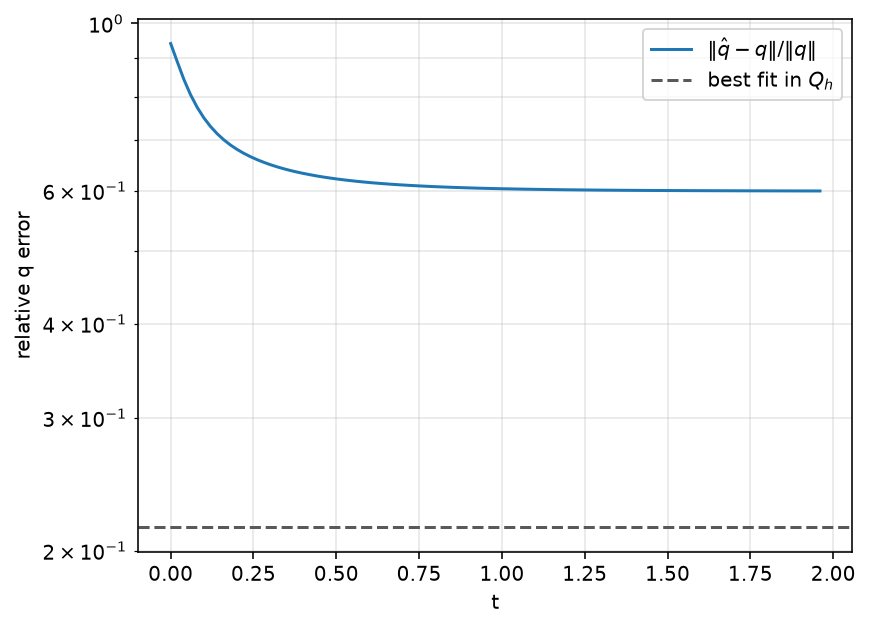

In [ ]:
# A headless kernel starts on the Agg backend: no figure ever reaches
# the notebook. The inline backend is what provides PNG figure output.
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

t = np.arange(len(result.error_q)) * result.meta["dt"]
plt.semilogy(t, result.error_q, label=r"$\|\hat q - q\| / \|q\|$")
plt.axhline(result.meta["q_floor"], color="0.55", ls=":",
            label=r"best fit in $Q_h$")
plt.xlabel("t")
plt.ylabel("relative q error")
plt.legend()
plt.grid(True, which="both", alpha=0.3)

### The checkpoint

Everything the run produced, read back from its file: the settings it ran
with, the error histories, and any stored step of the trajectory as a grid
function on the problem's spaces (the problem is built again from the
recorded constructor arguments).  `resume` continues the run from its
restart point -- after an interruption, or past `tend` -- extending the same
file.

{'problem': 'darcy', 'scheme': 'implicit', 'dt': np.float64(0.02), 'tend': np.float64(2.0), 'git': 'e5299b1eedd6ab376beb6dd2f7649ab8809b40b1+dirty'}
99 stored steps (every 1), final error_q 0.5997


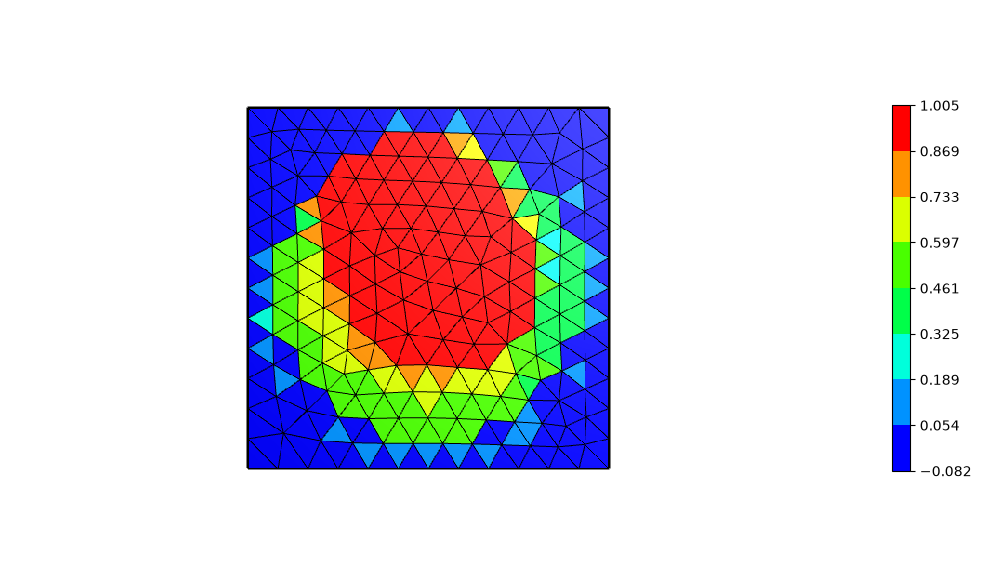

In [ ]:
from mras.checkpoint import load, resume
from mras.live import ROOT
from ngsplot import Plot

path = ROOT / "results" / f"{name}_noise{noise_level:g}.h5"
ckpt = load(path)
print({key: ckpt.attrs[key] for key in ("problem", "scheme", "dt", "tend", "git")})
print(f"{len(ckpt.steps)} stored steps (every {ckpt.attrs['stride']}), "
      f"final error_q {ckpt.history['error_q'][-1]:.4f}")
Plot(ckpt.field("q", -1), colorbar=True)

# result = resume(path, tend=400.0)   # continue the run to t = 400

The Burgers demo identifies the wake field $q$ around the hole row from the
flow driven by three beams of light, one turning about each hole, pulsing
and breathing in width at periods that never repeat; the other holes cast
shadows.  The parameter lives in discontinuous P1, whose best fit of $q$
(the dotted line in the strip) is 0.069% off at $h = 0.05$.  Noise-free at
the defaults ($h = 0.05$, $dt = 0.025$, `tend = 75`, implicit scheme),
$\|\hat q - q\| / \|q\|$ is about 0.66 at $t = 19$, 0.15 at 38, 0.043 at 56
and 0.011 at 75, still falling; a run takes about 45 minutes on 16 threads.
The light has to reach a region for $q$ to be identified there:
`burgers_1d_dark` turns the left beam off, and the left end of the
pipe stays near 13% error while the rest is recovered to about 1.5%.
Persistent excitation, not coercivity (A2), is what carries identifiability
for this gradient-coupled problem, and `docs/DEVIATIONS.md` records the
evidence and what the theory does and does not guarantee.